# Smooth responses over neighboring regions

An explicit adjacency graph lets neighboring regions share information. We compare an MRF smooth with independent region effects on held-out observations from the same regions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from nampy.gam import GAM

rng=np.random.default_rng(109)


## Define the adjacency graph

These nine regions form a three-by-three grid. The penalty uses graph neighbors, rather than treating region names as numerical coordinates.

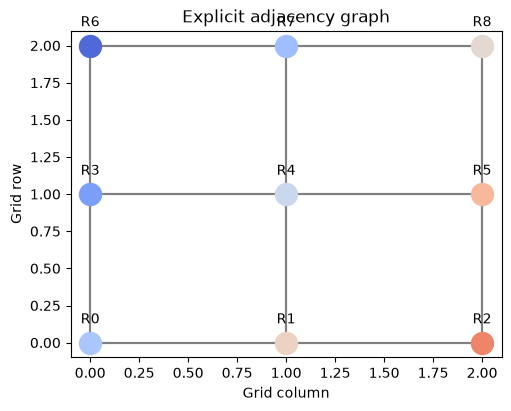

In [2]:
import json
regions=[f"R{i}" for i in range(9)]
positions={name:(i%3,i//3) for i,name in enumerate(regions)}
neighbors={name:[other for other in regions if abs(positions[name][0]-positions[other][0])+abs(positions[name][1]-positions[other][1])==1] for name in regions}
effect={name:.7*positions[name][0]-.4*positions[name][1] for name in regions}
frames=[]
for i,name in enumerate(regions):
    n=18 if i in [2,6] else 70
    frames.append(pd.DataFrame({"region":name,"y":effect[name]+rng.normal(0,1,n)}))
data=pd.concat(frames,ignore_index=True)
data["region"]=pd.Categorical(data.region,categories=regions)
train,test=train_test_split(data,test_size=.25,stratify=data.region,random_state=109)
figure,axis=plt.subplots(figsize=(5,4),constrained_layout=True)
for name in regions:
    x,y=positions[name]
    for other in neighbors[name]:
        ox,oy=positions[other]
        axis.plot([x,ox],[y,oy],color="grey",zorder=0)
    axis.scatter(x,y,s=250,c=[effect[name]],cmap="coolwarm",vmin=-1,vmax=2)
    axis.text(x,y+.13,name,ha="center")
axis.set(xlabel="Grid column",ylabel="Grid row",title="Explicit adjacency graph")
plt.show()
plt.close(figure)

## Fit and compare regional effects

The independent factor has an unpenalized coefficient per region. The MRF penalizes neighboring coefficient differences. Both are evaluated on the same test rows.

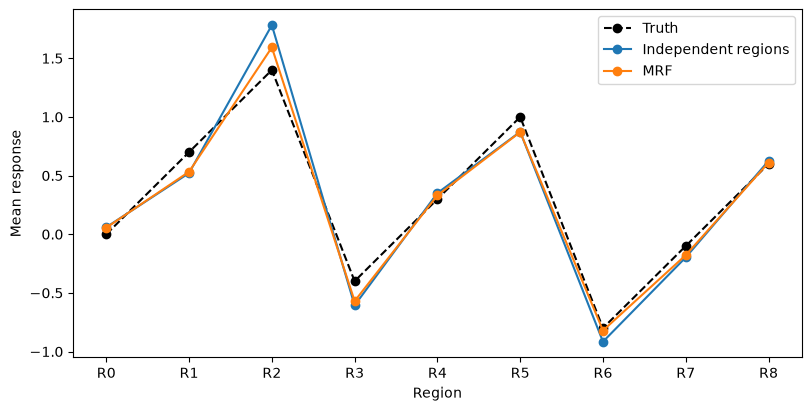

Model,Test RMSE
Independent regions,0.947
MRF,0.946


In [3]:
formula="y ~ s(region,bs='mrf',xt="+json.dumps({"nb":neighbors})+")"
models={"Independent regions":GAM(formula="y ~ region").fit(train),
        "MRF":GAM(formula=formula,optimize_smoothing=True,smoothing_method="reml").fit(train)}
grid=pd.DataFrame({"region":pd.Categorical(regions,categories=regions)})
figure,axis=plt.subplots(figsize=(8,4),constrained_layout=True)
axis.plot(regions,[effect[r] for r in regions],"k--o",label="Truth")
for name,model in models.items():axis.plot(regions,model.predict(grid),"o-",label=name)
axis.set(xlabel="Region",ylabel="Mean response")
axis.legend()
plt.show()
plt.close(figure)
pd.DataFrame([{"Model":name,"Test RMSE":mean_squared_error(test.y,m.predict(test))**.5} for name,m in models.items()]).style.hide(axis="index").format({"Test RMSE":"{:.3f}"})

Test RMSE is almost unchanged: 0.947 for independent regional effects and 0.946 for the MRF. The fitted effect plot shows the pooling differences, but this realization supplies little evidence of a predictive advantage.